In [1]:

import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
import pyarrow as pa
import pyarrow.dataset as ds
import pyarrow.compute as pc
from pathlib import Path
from scipy.spatial import cKDTree
import seaborn as sns
from utils import pq_to_xy, hex_offsets, hex_distance, plot_spatial_kernel_hex
from utils.spatial_RF import compute_kernel
from matplotlib.colors import TwoSlopeNorm,  SymLogNorm
from matplotlib.patches import RegularPolygon
# import matplotlib as mpl
pd.set_option('display.max_rows', 200)

In [2]:
data_dir = Path('results/connectome')

edges       = pd.read_feather(data_dir / 'edgelist_OL_columnar_T4T5norm.feather')
nodes_df    = pd.read_feather(data_dir / 'nodes_OL_columnar_T4T5norm.feather')

# edges       = pd.read_feather(data_dir / 'edgelist_OL_columnar.feather')
# nodes_df    = pd.read_feather(data_dir / 'nodes_OL_columnar.feather')
print("Available celltypes")
print("Number: ", nodes_df['cell_type'].nunique())
print(nodes_df['cell_type'].unique())

Available celltypes
Number:  24
['C2' 'C3' 'L1' 'L2' 'L3' 'L5' 'Mi1' 'Mi4' 'Mi9' 'T1' 'Tm1' 'Tm2' 'Tm20'
 'Tm4' 'Tm9' 'T4a' 'T4b' 'T4c' 'T4d' 'T5a' 'T5b' 'T5c' 'T5d' 'CT1']


- (dp, dq) = where the postsynaptic cell is relative to the input
- (-dp, -dq) = where the input is relative to the postsynaptic cell

## Example and mean kernels

In [3]:
mean_kernel, full_kernels = compute_kernel(
    edges,
    pre_type="CT1",
    post_type="T5b")

full_kernels

,post,target_p,target_q,post_side,dp,dq,count,signed_count,source_p,source_q,pre_cell_type,post_cell_type
0,98389,6.0,-10.0,right,-2,-2,0.0,0.0,4.0,-12.0,CT1,T5b
1,98389,6.0,-10.0,right,-2,-1,0.0,0.0,4.0,-11.0,CT1,T5b
2,98389,6.0,-10.0,right,-2,0,0.0,0.0,4.0,-10.0,CT1,T5b
3,98389,6.0,-10.0,right,-1,-2,0.0,0.0,5.0,-12.0,CT1,T5b
4,98389,6.0,-10.0,right,-1,-1,0.0,0.0,5.0,-11.0,CT1,T5b
...,...,...,...,...,...,...,...,...,...,...,...,...
16411,160169,-14.0,-3.0,right,1,1,0.0,0.0,-13.0,-2.0,CT1,T5b
16412,160169,-14.0,-3.0,right,1,2,0.0,0.0,-13.0,-1.0,CT1,T5b
16413,160169,-14.0,-3.0,right,2,0,0.0,0.0,-12.0,-3.0,CT1,T5b
16414,160169,-14.0,-3.0,right,2,1,0.0,0.0,-12.0,-2.0,CT1,T5b


/home/guardomayas/NUIN/sjbcs/male_cns_var/utils/plotting.py:263: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.88, 1]) #[left, bottom, right, top]


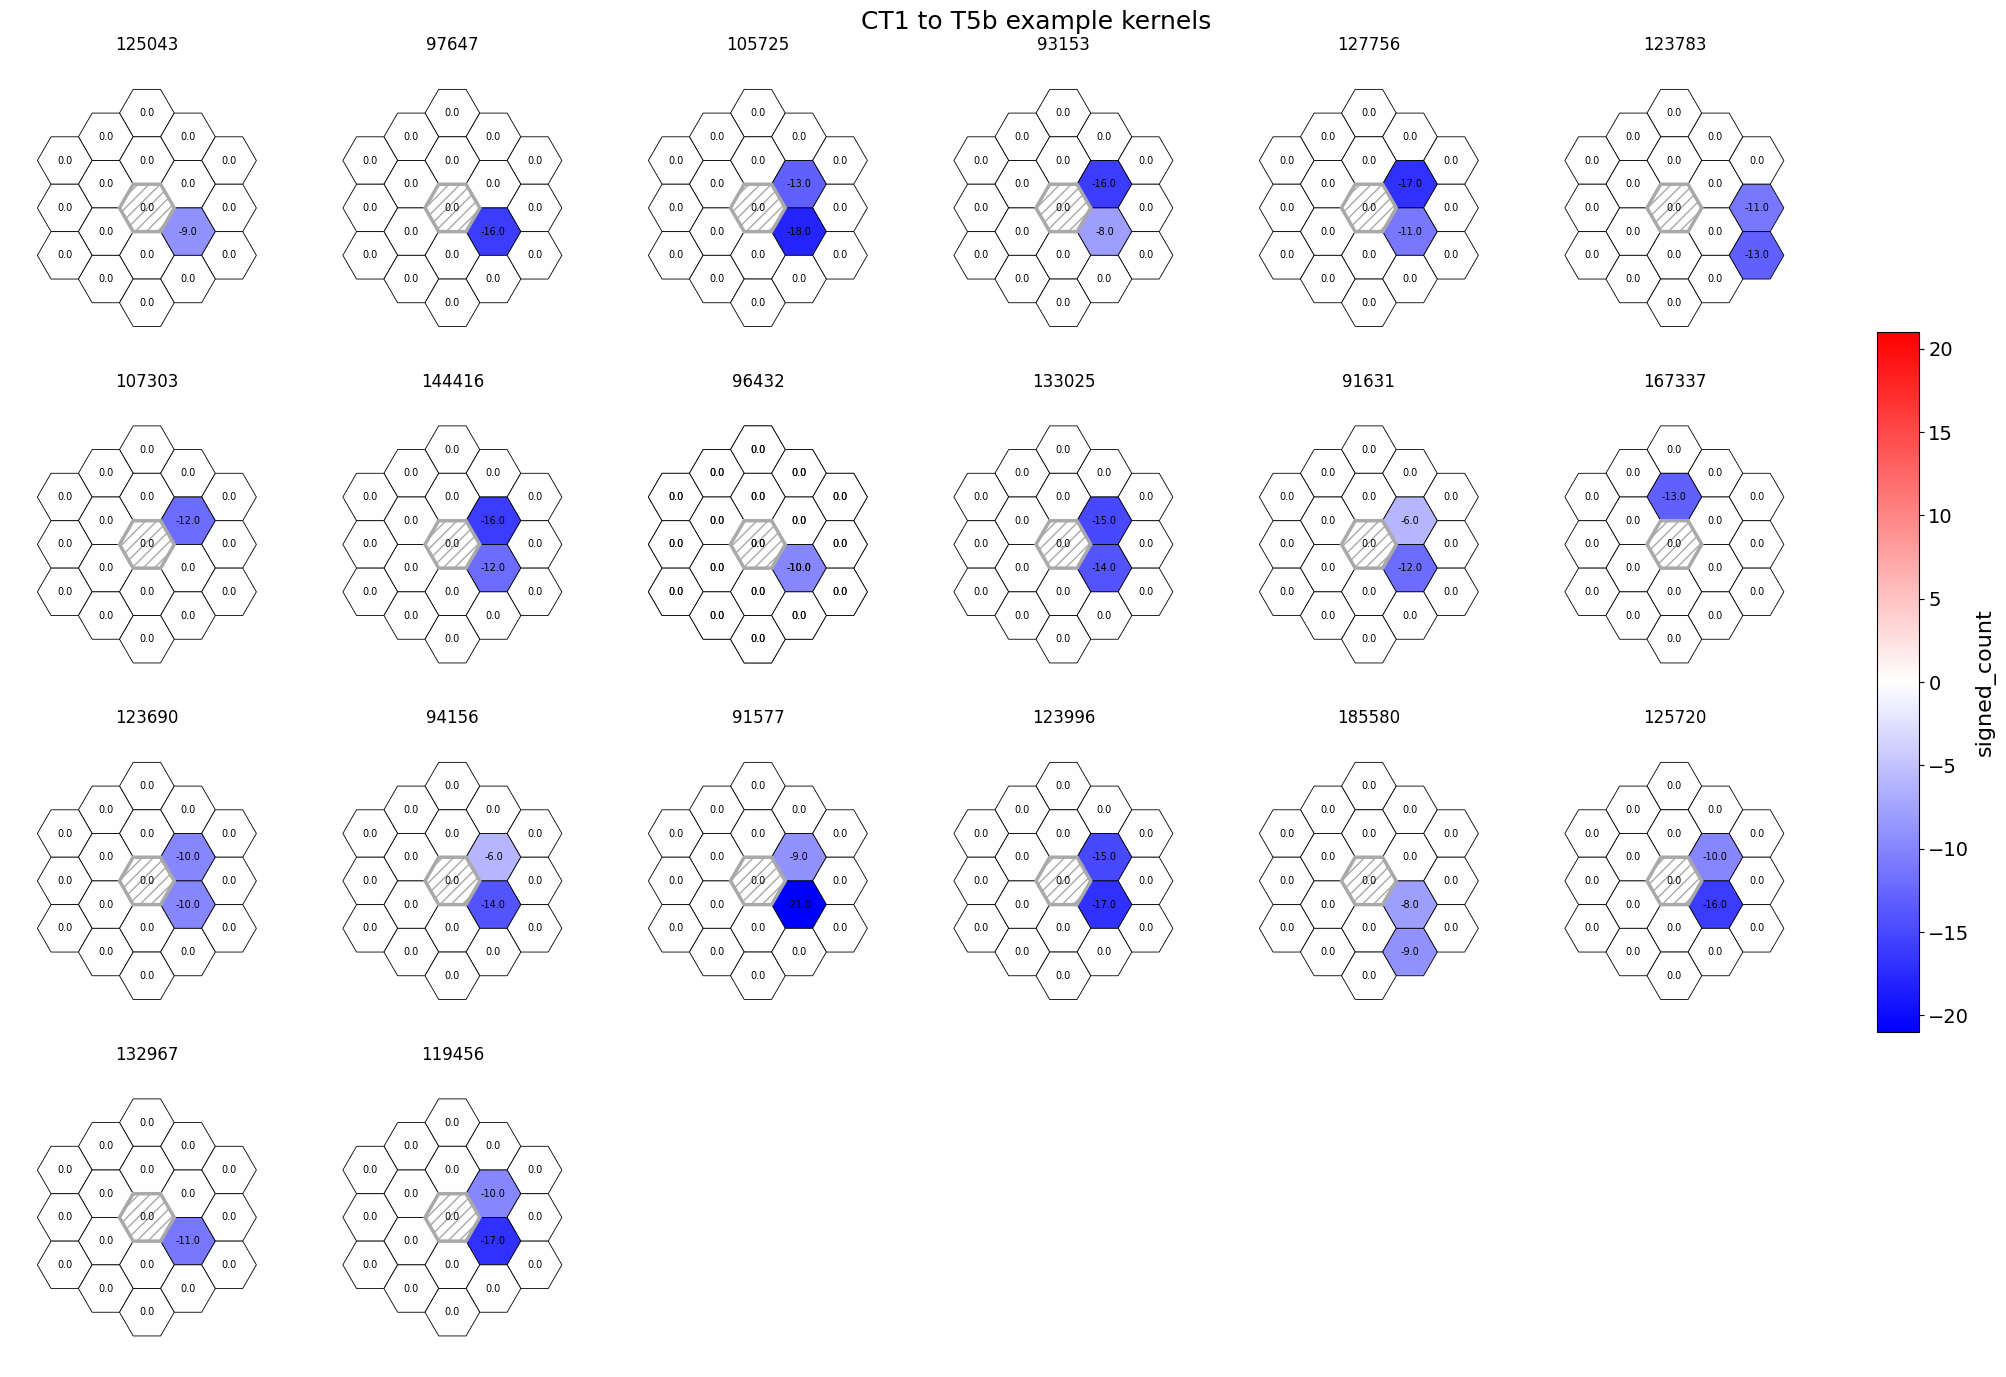

In [4]:
from utils.plotting import plot_example_RFs
n_samples = 20
plot_example_RFs(full_kernels, 
                n_samples = n_samples,
                max_cols = 6
                 )

<Axes: title={'center': 'CT1 to T5b mean kernel'}>

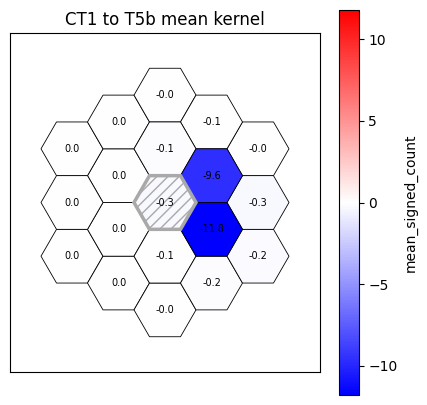

In [5]:
plot_spatial_kernel_hex(mean_kernel, value_col="mean_signed_count", 
                        radius=4, 
                        add_colorbar=True, 
                        title= f"{full_kernels['pre_cell_type'].iloc[0]} to "
    f"{full_kernels['post_cell_type'].iloc[0]} mean kernel")

In [6]:
from utils.plotting import plot_kernels_on_eye

# def plot_kernels_on_eye(full_kernels, n_samples, seed=1):
#     df = full_kernels.copy()

#     post_ids  = _get_sample_ids(full_kernels, n_samples, seed=seed)
#     plot_df = full_kernels[full_kernels["post"].isin(post_ids)].copy()
#     # Absolute presynaptic/input column coordinates
#     plot_df["input_p"] = plot_df["target_p"] - plot_df["dp"]
#     plot_df["input_q"] = plot_df["target_q"] - plot_df["dq"]

#     # Collapse in case multiple rows map to same input column for same post cell
#     plot_df = (
#         plot_df
#         .groupby(["post", "target_p", "target_q", "input_p", "input_q"], as_index=False)
#         .agg(signed_count=("signed_count", "sum"))
#     )

#     # Background eye map: all T5 home columns in this full table
#     eye = (
#         df[["target_p", "target_q"]]
#         .dropna()
#         .drop_duplicates()
#         .rename(columns={"target_p": "p", "target_q": "q"})
#     )

#     x_eye, y_eye = pq_to_xy(
#         eye["p"].to_numpy(),
#         eye["q"].to_numpy(),
#         hexsize=1.0,
#         rotate=-np.pi / 6,
#     )

#     eye["x_plot"] = x_eye
#     eye["y_plot"] = y_eye

#     # Input columns for the selected cells
#     x_in, y_in = pq_to_xy(
#         plot_df["input_p"].to_numpy(),
#         plot_df["input_q"].to_numpy(),
#         hexsize=1.0,
#         rotate=-np.pi / 6,
#     )

#     plot_df["x_plot"] = x_in
#     plot_df["y_plot"] = y_in

#     # Home columns for the selected cells
#     homes = (
#         plot_df[["post", "target_p", "target_q"]]
#         .drop_duplicates()
#         .rename(columns={"target_p": "p", "target_q": "q"})
#     )

#     x_home, y_home = pq_to_xy(
#         homes["p"].to_numpy(),
#         homes["q"].to_numpy(),
#         hexsize=1.0,
#         rotate=-np.pi / 6,
#     )

#     homes["x_plot"] = x_home
#     homes["y_plot"] = y_home

#     mirror_y = True
#     if mirror_y:
#         eye["y_plot"] = -eye["y_plot"]
#         plot_df["y_plot"] = -plot_df["y_plot"]
#         homes["y_plot"] = -homes["y_plot"]
#     hexsize = 1.0
#     cmap = plt.get_cmap("bwr")
#     vmax = np.nanmax(np.abs(plot_df['signed_count']))

#     norm = TwoSlopeNorm(
#         vmin=-vmax,
#         vcenter=0,
#         vmax=vmax
#     )

#     # norm = SymLogNorm(
#     #     linthresh=1,      # values between -1 and 1 are linear
#     #     linscale=1,
#     #     vmin=-vmax,
#     #     vmax=vmax,
#     #     base=10
#     # )

#     fig, ax = plt.subplots(figsize=(8, 8))

#     # 1. Plot all T columns as pale background
#     for _, row in eye.iterrows():
#         ax.add_patch(
#             RegularPolygon(
#                 (row["x_plot"], row["y_plot"]),
#                 numVertices=6,
#                 radius=hexsize * 0.95,
#                 orientation=np.pi / 6,
#                 facecolor="lightgray",
#                 edgecolor="white",
#                 linewidth=0.4,
#                 alpha=0.6,
#             )
#         )

#     # 2. Plot selected input columns colored by synapse count
#     # Draw only nonzero input bins if desired
#     nonzero_inputs = plot_df[plot_df["signed_count"] != 0].copy()

#     for _, row in nonzero_inputs.iterrows():
#         ax.add_patch(
#             RegularPolygon(
#                 (row["x_plot"], row["y_plot"]),
#                 numVertices=6,
#                 radius=hexsize * 0.95,
#                 orientation=np.pi / 6,
#                 facecolor=cmap(norm(row["signed_count"])),
#                 edgecolor="black",
#                 linewidth=0.6,
#                 alpha=0.9,
#             )
#         )

#     # 3. Highlight the three T home columns by darkening/outline
#     for _, row in homes.iterrows():
#         ax.add_patch(
#             RegularPolygon(
#                 (row["x_plot"], row["y_plot"]),
#                 numVertices=6,
#                 radius=hexsize * 0.95,
#                 orientation=np.pi / 6,
#                 facecolor="none",
#                 edgecolor="black",
#                 linewidth=2.5,
#                 hatch="///",
#             )
#         )

#     sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
#     sm.set_array([])
#     fig.colorbar(sm, ax=ax, shrink=0.75, label="input synapse count")

#     ax.set_aspect("equal")
#     ax.autoscale_view()
#     ax.axis("off")

#     fig.suptitle(
#         f"{full_kernels['pre_cell_type'].iloc[0]} to "
#         f"{full_kernels['post_cell_type'].iloc[0]} example kernels",
#         fontsize=18,
#     )

#     plt.show()
    
plot_kernels_on_eye(full_kernels, n_samples, seed=1)

ImportError: cannot import name 'plot_kernels_on_eye' from 'utils.plotting' (/home/guardomayas/NUIN/sjbcs/male_cns_var/utils/plotting.py)

In [ ]:
post_type = "T4b"
post_type_inputs = df = edges.query(
        "post_cell_type == @post_type"
    ).copy()
input_types = post_type_inputs['pre_cell_type'].unique()

value_col = "mean_signed_count"
# post_type = "T4b"

kernels = {}

for pre_type in input_types:
    mean_kernel, full = compute_kernel(
        edges,
        pre_type=pre_type,
        post_type=post_type,
        radius=3
    )
    kernels[pre_type] = mean_kernel
    
threshold = 2.5

kernel_strength = {
    pre_type: kernels[pre_type][value_col].abs().max()
    for pre_type in input_types
}

input_types = [
    pre_type
    for pre_type in input_types
    if kernel_strength[pre_type] >= threshold
]

input_types = sorted(
    input_types,
    key=lambda pre_type: kernel_strength[pre_type],
    reverse=True
)

## Mean kernels for a given post type

In [ ]:

from matplotlib.colors import TwoSlopeNorm,  SymLogNorm
all_vals = np.concatenate([
    k[value_col].to_numpy()
    for k in kernels.values()
])

vmax = np.nanmax(np.abs(all_vals))*0.8

norm = TwoSlopeNorm(
    vmin=-vmax,
    vcenter=0,
    vmax=vmax
)

# norm = SymLogNorm(
#     linthresh=1,      # values between -1 and 1 are linear
#     linscale=1,
#     vmin=-vmax,
#     vmax=vmax,
#     base=10
# )

import math
n = len(input_types)
ncols = min(4, n)
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(2 * ncols, 2 * nrows),
    squeeze=False
)

axes_flat = axes.flatten()

for ax, pre_type in zip(axes_flat, input_types):
    plot_spatial_kernel_hex(
        kernels[pre_type],
        value_col=value_col,
        radius=2,
        cmap="bwr",
        norm=norm,
        ax=ax,
        title=f"{pre_type} → {post_type}",
        plot_labels=True, 
        use_input_relative_to_target=True,
        mirror_x=True,
        mirror_y=True,
    )


for ax in axes_flat:
    ax.axis("off")

# Common colorbar
sm = plt.cm.ScalarMappable(norm=norm, cmap=plt.get_cmap("bwr"))
sm.set_array([])
plt.tight_layout(rect=[0, 0, 0.88, 1]) #[left, bottom, right, top]

cax = fig.add_axes([0.97, 0.25, 0.02, 0.5]) # [left, bottom, width, height]
cbar = fig.colorbar(
    sm,
    cax=cax,
    shrink=0.4,
    location="right",
    label="Mean signed synapse count"
)

# fig.suptitle(f"Signed spatial input kernels onto {post_type}", fontsize=16, y=1.02)

fig.tight_layout()
fig.savefig(f"images/{post_type}_input_RF.png", dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# Use either all input types, or the thresholded/sorted input_types from above
types_to_include = input_types  # thresholded list
# types_to_include = list(kernels.keys())  # all presynaptic types

avg_rf = (
    pd.concat(
        [
            kernels[pre_type][["dp", "dq", value_col]].assign(pre_cell_type=pre_type)
            for pre_type in types_to_include
        ],
        ignore_index=True
    )
    .groupby(["dp", "dq"], as_index=False)
    .agg(total_mean_signed_count=(value_col, "sum"))
)

from matplotlib.colors import TwoSlopeNorm

rf_value_col = "total_mean_signed_count"

vmax = np.nanmax(np.abs(avg_rf[rf_value_col]))

norm = TwoSlopeNorm(
    vmin=-vmax,
    vcenter=0,
    vmax=vmax
)

fig, ax = plt.subplots(figsize=(4, 4))

plot_spatial_kernel_hex(
    avg_rf,
    value_col=rf_value_col,
    radius=2,
    cmap="bwr",
    norm=norm,
    ax=ax,
    title=f"Average signed input RF onto {post_type}",
    plot_labels=True,
    use_input_relative_to_target=True,
    mirror_x=True,
    mirror_y=True,
)

ax.axis("off")

sm = plt.cm.ScalarMappable(norm=norm, cmap=plt.get_cmap("bwr"))
sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    shrink=0.75,
    label="Total mean signed synapse count"
)

plt.tight_layout()
plt.show()